In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files


In [2]:

# Load dataset
df = pd.read_csv("retail_sales_cleaned.csv")


Saving retail_sales_cleaned.csv to retail_sales_cleaned (1).csv


In [10]:
df_fe = df.copy()

print("Feature engineering workspace created!")

Feature engineering workspace created!


In [11]:
# Extract date components

df_fe["order_year"] = df_fe["order_date"].dt.year

df_fe["order_month"] = df_fe["order_date"].dt.month

df_fe["order_month_name"] = df_fe["order_date"].dt.month_name()

df_fe["order_quarter"] = (
    "Q" + df_fe["order_date"].dt.quarter.astype(str)
)

df_fe["order_day"] = df_fe["order_date"].dt.day

df_fe["day_of_week"] = df_fe["order_date"].dt.day_name()

df_fe["is_weekend"] = (
    df_fe["order_date"].dt.dayofweek >= 5
)

print("Date features created!")

Date features created!


In [12]:
# Customer spending

customer_spending = (
    df_fe.groupby("customer_id")["net_sales"]
    .sum()
    .reset_index()
)

customer_spending.columns = [
    "customer_id",
    "customer_total_spending"
]

df_fe = df_fe.merge(
    customer_spending,
    on="customer_id",
    how="left"
)

print("Customer spending feature created!")

Customer spending feature created!


In [13]:
# Customer spending segmentation

df_fe["customer_segment"] = pd.qcut(
    df_fe["customer_total_spending"].rank(method="first"),
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ]
)

print(df_fe["customer_segment"].value_counts())

customer_segment
Low Value          1250
Medium Value       1250
High Value         1250
Very High Value    1250
Name: count, dtype: int64


In [14]:
# Classify order values

df_fe["order_value_category"] = pd.cut(
    df_fe["net_sales"],
    bins=[
        -np.inf,
        50000,
        150000,
        300000,
        np.inf
    ],
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Premium Value"
    ]
)

print(
    df_fe["order_value_category"].value_counts()
)

order_value_category
Low Value        2163
Medium Value     1803
High Value        544
Premium Value     490
Name: count, dtype: int64


In [15]:
# Discount classification

df_fe["discount_category"] = pd.cut(
    df_fe["discount_pct"],
    bins=[
        -0.001,
        0,
        0.05,
        0.10,
        0.15,
        1
    ],
    labels=[
        "No Discount",
        "Low Discount",
        "Moderate Discount",
        "High Discount",
        "Very High Discount"
    ]
)

print(df_fe["discount_category"].value_counts())

discount_category
No Discount           1803
Low Discount          1259
Moderate Discount     1042
High Discount          659
Very High Discount     237
Name: count, dtype: int64


In [16]:
# Profitability classification

df_fe["profitability_category"] = np.select(
    [
        df_fe["profit_margin_pct"] < 10,
        df_fe["profit_margin_pct"].between(10, 25, inclusive="left"),
        df_fe["profit_margin_pct"].between(25, 40, inclusive="left"),
        df_fe["profit_margin_pct"] >= 40
    ],
    [
        "Low Profitability",
        "Moderate Profitability",
        "Good Profitability",
        "High Profitability"
    ],
    default="Unknown"
)

print(
    df_fe["profitability_category"].value_counts()
)

profitability_category
High Profitability        2072
Good Profitability        1755
Moderate Profitability     980
Low Profitability          193
Name: count, dtype: int64


In [17]:
# Delivery speed classification

df_fe["delivery_performance"] = np.select(
    [
        df_fe["shipping_days"] <= 2,
        df_fe["shipping_days"].between(3, 5),
        df_fe["shipping_days"] > 5
    ],
    [
        "Fast Delivery",
        "Standard Delivery",
        "Slow Delivery"
    ],
    default="Unknown"
)

print(df_fe["delivery_performance"].value_counts())

delivery_performance
Standard Delivery    2625
Fast Delivery        1670
Slow Delivery         705
Name: count, dtype: int64


In [18]:
# Count order lines per customer

customer_frequency = (
    df_fe.groupby("customer_id")["order_line_id"]
    .nunique()
    .reset_index()
)

customer_frequency.columns = [
    "customer_id",
    "customer_order_frequency"
]

# Merge into main dataset

df_fe = df_fe.merge(
    customer_frequency,
    on="customer_id",
    how="left"
)

print("Customer frequency created!")

Customer frequency created!


In [19]:
df_fe["purchase_frequency_category"] = np.select(
    [
        df_fe["customer_order_frequency"] == 1,
        df_fe["customer_order_frequency"].between(2, 4),
        df_fe["customer_order_frequency"] >= 5
    ],
    [
        "One-Time Customer",
        "Occasional Customer",
        "Frequent Customer"
    ],
    default="Unknown"
)

print(
    df_fe["purchase_frequency_category"].value_counts()
)

purchase_frequency_category
Frequent Customer      3042
Occasional Customer    1866
One-Time Customer        92
Name: count, dtype: int64


In [20]:
# Recognised revenue for delivered orders only

df_fe["recognised_revenue"] = np.where(
    df_fe["order_status"] == "Delivered",
    df_fe["net_sales"],
    0
)

# Recognised profit for delivered orders only

df_fe["recognised_profit"] = np.where(
    df_fe["order_status"] == "Delivered",
    df_fe["profit"],
    0
)

print("Recognised revenue and profit created!")

Recognised revenue and profit created!


## Analyse the newly engineered features
A. Customer segmentation analysis

In [22]:
customer_segment_analysis = (
    df_fe.groupby("customer_segment", observed=True)
    .agg(
        Customers=("customer_id", "nunique"),
        Revenue=("recognised_revenue", "sum"),
        Profit=("recognised_profit", "sum")
    )
)

print(customer_segment_analysis)

                  Customers      Revenue      Profit
customer_segment                                    
Low Value               446   52699310.0  20302910.0
Medium Value            268   78575585.0  29500285.0
High Value              243  136395170.0  40249670.0
Very High Value         229  346543575.0  77896375.0


B. Order value analysis

In [23]:
order_value_analysis = (
    df_fe.groupby("order_value_category", observed=True)
    .agg(
        Order_Lines=("order_line_id", "count"),
        Revenue=("recognised_revenue", "sum"),
        Profit=("recognised_profit", "sum")
    )
)

print(order_value_analysis)

                      Order_Lines      Revenue      Profit
order_value_category                                      
Low Value                    2163   49361065.0  18238865.0
Medium Value                 1803  124264005.0  49069605.0
High Value                    544   80776180.0  29095180.0
Premium Value                 490  359812390.0  71545590.0


C. Weekend versus weekday sales

In [24]:
weekend_analysis = (
    df_fe.groupby("is_weekend")
    .agg(
        Order_Lines=("order_line_id", "count"),
        Revenue=("recognised_revenue", "sum"),
        Profit=("recognised_profit", "sum")
    )
)

weekend_analysis.index = [
    "Weekday" if not x else "Weekend"
    for x in weekend_analysis.index
]

print(weekend_analysis)

         Order_Lines      Revenue       Profit
Weekday         3621  435461195.0  119573495.0
Weekend         1379  178752445.0   48375745.0


D. Delivery performance analysis

In [25]:
delivery_analysis = (
    df_fe.groupby("delivery_performance")
    .agg(
        Order_Lines=("order_line_id", "count"),
        Revenue=("recognised_revenue", "sum")
    )
)

print(delivery_analysis)

                      Order_Lines      Revenue
delivery_performance                          
Fast Delivery                1670  199374555.0
Slow Delivery                 705   97683735.0
Standard Delivery            2625  317155350.0


## Refine customer features using delivered orders

In [26]:
# Calculate customer spending using delivered orders only

delivered_customers = (
    df_fe.groupby("customer_id")
    .agg(
        customer_total_spending=(
            "recognised_revenue", "sum"
        ),
        delivered_order_frequency=(
            "order_status",
            lambda x: (x == "Delivered").sum()
        )
    )
    .reset_index()
)

# Remove earlier customer features before replacing them

df_fe = df_fe.drop(
    columns=[
        "customer_total_spending",
        "customer_order_frequency",
        "customer_segment",
        "purchase_frequency_category"
    ],
    errors="ignore"
)

# Merge updated customer features

df_fe = df_fe.merge(
    delivered_customers,
    on="customer_id",
    how="left"
)

# Create spending segments

df_fe["customer_segment"] = pd.qcut(
    df_fe["customer_total_spending"].rank(method="first"),
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ]
)

# Classify purchase frequency

df_fe["purchase_frequency_category"] = np.select(
    [
        df_fe["delivered_order_frequency"] == 1,
        df_fe["delivered_order_frequency"].between(2, 4),
        df_fe["delivered_order_frequency"] >= 5
    ],
    [
        "One-Time Customer",
        "Occasional Customer",
        "Frequent Customer"
    ],
    default="No Delivered Orders"
)

print("Customer features refined successfully!")

Customer features refined successfully!


## Visualise our engineered features

Customer segments

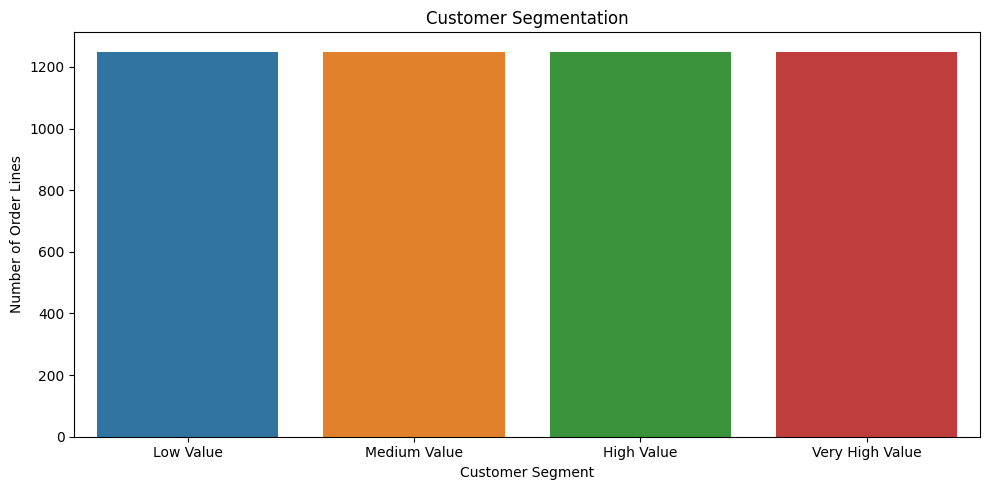

In [27]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_fe,
    x="customer_segment",
    hue="customer_segment",
    order=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Very High Value"
    ],
    legend=False
)

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Order Lines")

plt.tight_layout()
plt.show()

Profitability categories

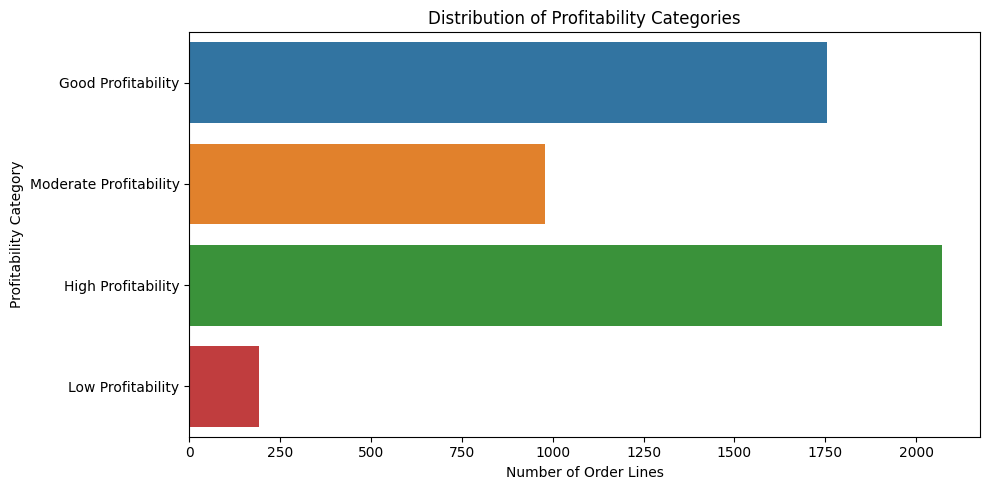

In [29]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_fe,
    y="profitability_category",
    hue="profitability_category",
    legend=False
)

plt.title("Distribution of Profitability Categories")
plt.xlabel("Number of Order Lines")
plt.ylabel("Profitability Category")

plt.tight_layout()
plt.show()

Perform final validation

In [30]:
print("FINAL FEATURE ENGINEERING REPORT")
print("--------------------------------")

print("Total records:", df_fe.shape[0])
print("Total columns:", df_fe.shape[1])

print("Duplicate records:", df_fe.duplicated().sum())

print("Missing values:", df_fe.isnull().sum().sum())

print("\nNew features:")
print(df_fe.columns.tolist())

print("\nSample records:")
display(df_fe.head())

FINAL FEATURE ENGINEERING REPORT
--------------------------------
Total records: 5000
Total columns: 44
Duplicate records: 0
Missing values: 0

New features:
['order_line_id', 'order_date', 'customer_id', 'gender', 'age', 'city', 'state', 'product', 'category', 'quantity', 'unit_price_ngn', 'unit_cost_ngn', 'discount_pct', 'payment_method', 'sales_channel', 'shipping_days', 'order_status', 'gross_sales', 'discount_amount', 'net_sales', 'total_cost', 'profit', 'profit_margin_pct', 'year', 'month', 'month_name', 'quarter', 'order_year', 'order_month', 'order_month_name', 'order_quarter', 'order_day', 'day_of_week', 'is_weekend', 'order_value_category', 'discount_category', 'profitability_category', 'delivery_performance', 'recognised_revenue', 'recognised_profit', 'customer_total_spending', 'delivered_order_frequency', 'customer_segment', 'purchase_frequency_category']

Sample records:


,order_line_id,order_date,customer_id,gender,age,city,state,product,category,quantity,...,order_value_category,discount_category,profitability_category,delivery_performance,recognised_revenue,recognised_profit,customer_total_spending,delivered_order_frequency,customer_segment,purchase_frequency_category
0,OL00001,2025-07-30,CUST0616,Female,43,Enugu,Enugu,T-Shirt,Fashion,2,...,Low Value,Moderate Discount,Good Profitability,Slow Delivery,0.0,0.0,714235.0,5,High Value,Frequent Customer
1,OL00002,2024-08-30,CUST0082,Male,29,Port Harcourt,Rivers,Smartphone,Electronics,1,...,High Value,Moderate Discount,Moderate Profitability,Standard Delivery,180180.0,44380.0,330020.0,4,Medium Value,Occasional Customer
2,OL00003,2025-03-27,CUST0556,Female,24,Yaba,Lagos,Makeup Kit,Beauty,5,...,High Value,Low Discount,High Profitability,Standard Delivery,152475.0,82975.0,399335.0,4,High Value,Occasional Customer
3,OL00004,2025-07-01,CUST0240,Male,40,Benin City,Edo,Rice 10Kg,Groceries,1,...,Low Value,No Discount,Moderate Profitability,Fast Delivery,23100.0,3400.0,54200.0,2,Low Value,Occasional Customer
4,OL00005,2024-09-21,CUST0762,Male,42,Ibadan,Oyo,Smartphone,Electronics,2,...,Premium Value,Moderate Discount,Moderate Profitability,Standard Delivery,334260.0,65260.0,725270.0,5,High Value,Frequent Customer


Export CSV

In [31]:
df_fe.to_csv(
    "retail_sales_feature_engineered.csv",
    index=False
)

print("CSV exported successfully!")

CSV exported successfully!


In [33]:
files.download(
    "retail_sales_feature_engineered.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Export Excel

In [32]:
df_fe.to_excel(
    "retail_sales_feature_engineered.xlsx",
    index=False
)

print("Excel exported successfully!")

Excel exported successfully!


In [34]:
files.download(
    "retail_sales_feature_engineered.xlsx"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>